# P3(a): rolling one-day-ahead variance forecasts, five selectors
Rules are frozen (D-023). Expanding window, whole selector refit every `forecast.refit_every` test days, fixed parameters re-filtered in between (D-024 to D-027). All logic lives in `src/forecast.py`; this notebook only calls it and shows the output.

Set `forecast.smoke: false` in `config.yaml` for the full run (all pairs, full test period). With `smoke: true` it runs the first pair only, on the last `forecast.smoke_days` test days.

In [1]:
# GOAL: run the five selectors (rolling_var, fixed_garch11, acf_only, grid_bic, hybrid) through the
# no-look-ahead rolling forecast for every pair, and write results/forecasts_<pair>.csv.
#
# How to read the output (one table per pair, one row per selector):
#   rows            = number of forecast days (the same for all five selectors)
#   models_fitted   = total GARCH fits over the test period (cost of the selection; 0 for rolling_var)
#   refits          = number of refit blocks (one per forecast.refit_every days)
#   no_valid_fit    = number of REFITS whose every fit was rejected; those blocks used the rolling variance
#   flagged         = number of refits flagged (hybrid: gate failed after escalation; baselines: no valid fit)
# Nothing here says which selector is better: that needs the losses (QLIKE, DM), which come later.

import sys                      # lets us edit Python's module search path
from pathlib import Path        # object-style file paths

# Find the project root (the folder that contains src/), whether we run from it or from notebooks/.
root = Path.cwd()
if not (root / 'src').exists():
    root = root.parent
sys.path.insert(0, str(root))   # put the project root first so 'from src...' works

from src.data import load_config         # config.yaml reader
from src.forecast import run_all         # all pairs x all selectors, writes the CSVs

cfg = load_config()   # every threshold, window, seed and the smoke switch come from config.yaml
print('smoke mode:', cfg['forecast']['smoke'])

results = run_all(cfg)   # dict: pair -> DataFrame (also saved as results/forecasts_<pair>.csv)

for pair, df in results.items():
    print(f'\n{pair}: {len(df)} rows, {df["date"].min()} to {df["date"].max()}')

    # One row per selector. A refit is identified by its refit_date; the flags repeat on every row of a block,
    # so we count them once per block (first row of each block).
    first = df.drop_duplicates(['selector', 'refit_date'])
    table = first.groupby('selector', sort=False).agg(refits=('refit_date', 'size'),
                                                      no_valid_fit=('no_valid_fit', 'sum'),
                                                      flagged=('flagged', 'sum'))
    table.insert(0, 'rows', df.groupby('selector', sort=False).size())
    table.insert(1, 'models_fitted', df.groupby('selector', sort=False)['models_fitted'].sum())
    display(table)

smoke mode: False



DEXUSEU: 4190 rows, 2023-05-30 00:00:00 to 2026-10-02 00:00:00


,rows,models_fitted,refits,no_valid_fit,flagged
selector,,,,,
rolling_var,838,0,42,0,0
fixed_garch11,838,42,42,0,0
acf_only,838,42,42,0,0
grid_bic,838,1260,42,0,0
hybrid,838,42,42,0,0



DEXJPUS: 4190 rows, 2023-05-30 00:00:00 to 2026-10-02 00:00:00


,rows,models_fitted,refits,no_valid_fit,flagged
selector,,,,,
rolling_var,838,0,42,0,0
fixed_garch11,838,42,42,0,0
acf_only,838,42,42,0,0
grid_bic,838,1260,42,0,0
hybrid,838,42,42,0,0



DEXINUS: 4190 rows, 2023-05-30 00:00:00 to 2026-10-02 00:00:00


,rows,models_fitted,refits,no_valid_fit,flagged
selector,,,,,
rolling_var,838,0,42,0,0
fixed_garch11,838,42,42,32,32
acf_only,838,42,42,32,32
grid_bic,838,1260,42,0,0
hybrid,838,142,42,28,30


# P3(b): losses, Diebold-Mariano tests, fit-failure columns
Protocol in `docs/decision.md` D-028 (written before any number). QLIKE is the primary loss, MSE the secondary check; the DM test uses Newey-West and raw p-values (no multiplicity correction is applied: 60 tests in a full table, so read single small p-values with care). Rules stay frozen (D-023). All logic is in `src/evaluate.py`; the cells below only call it and write `results/loss_table.csv` and `results/dm_table.csv`.

Run order: the user first copies the previous CSVs to `results/forecasts_<pair>_p3a.csv`, then runs this notebook, so the regression check below compares the new forecasts with the old ones.

In [2]:
# GOAL: prove that adding the new bookkeeping columns changed NO forecast. We compare the h column of the
# rerun above with the CSV saved before P3(b) (results/forecasts_<pair>_p3a.csv).
#
# How to read the output: one line per pair with the largest absolute difference in h over all selectors
# and days. It must print 0.0 exactly. Anything above 0 means a forecast changed and P3(b) is NOT
# observation-only: stop and report it. Both files are read back from CSV with the same reader so that
# parsing cannot add a rounding difference of its own.

import pandas as pd                                   # CSV reading
from src.evaluate import max_abs_h_diff              # largest |h_new - h_old| over matched (date, selector) rows

results_dir = root / cfg['paths']['results_dir']      # results/ folder from config.yaml

for pair in cfg['pairs']:
    new = pd.read_csv(results_dir / f'forecasts_{pair}.csv')       # file just written by run_all
    old = pd.read_csv(results_dir / f'forecasts_{pair}_p3a.csv')   # copy of the previous run
    print(pair, 'max abs diff in h:', max_abs_h_diff(new, old))

DEXUSEU max abs diff in h: 0.0
DEXJPUS max abs diff in h: 0.0
DEXINUS max abs diff in h: 0.0


In [3]:
# GOAL: build the two result tables from the forecast CSVs and save them.
#   results/loss_table.csv : one row per pair x selector (losses, cost, how often the selector fell back)
#   results/dm_table.csv   : Diebold-Mariano tests per pair x loss x sample x comparison
#
# How to read loss_table: lower qlike (primary) and mse (secondary) are better. models_fitted is the cost.
# escalation_rate = share of refits that needed more than one fit (empty for grid_bic: it always fits 30 models,
# so the share would be 1 by construction); fallback_share = share of refits that used the rolling variance because
# every fit was rejected; valid_day_qlike = QLIKE on the selector's own valid days only; agree_grid = share of refits
# whose order equals grid_bic's, counted only on refits where BOTH had a valid fit (n_both_valid says how many).
# How to read dm_table: mean_diff = mean(loss_A - loss_B), so a NEGATIVE dm means A (hybrid, or grid_bic in
# the last comparison) is better; p is a raw two-sided normal p-value with NO multiplicity correction.
# dm_L20 / p_L20 = the same test with the Newey-West bandwidth set to 20 days (one refit block) instead of the formula
# bandwidth L in column L. A result is called ROBUST only if p < 0.05 AND p_L20 < 0.05 (D-029); significant under one
# bandwidth only means "not robust to the bandwidth".
# status 'identical' = the two forecast series coincide, so there is nothing to test (dm and p are empty).
# sample 'all' is the primary sample; 'common_valid' drops days where either selector used the fallback.

import pandas as pd                                    # CSV reading
from src.evaluate import loss_table, dm_table          # all the statistics live in src/evaluate.py

forecasts = {pair: pd.read_csv(results_dir / f'forecasts_{pair}.csv', parse_dates=['date', 'refit_date'])
             for pair in cfg['pairs']}                 # read back from disk: the tables describe the saved files

lt = loss_table(forecasts, cfg)
dt = dm_table(forecasts, cfg)

lt.to_csv(results_dir / 'loss_table.csv', index=False)  # saved for the report
dt.to_csv(results_dir / 'dm_table.csv', index=False)

display(lt)
display(dt[dt['loss'] == cfg['evaluate']['primary_loss']])   # primary loss on screen; MSE rows are in the CSV

,pair,selector,qlike,mse,models_fitted,refits,escalation_rate,modal_order_share,agree_grid,n_both_valid,fallback_share,valid_day_qlike
0,DEXUSEU,rolling_var,-0.753387,0.130434,0,42,0.000000,NaN,NaN,NaN,0.000000,-0.753387
1,DEXUSEU,fixed_garch11,-0.763000,0.130345,42,42,0.000000,1.000000,1.0,42.0,0.000000,-0.763000
2,DEXUSEU,acf_only,-0.763000,0.130345,42,42,0.000000,1.000000,1.0,42.0,0.000000,-0.763000
3,DEXUSEU,grid_bic,-0.763000,0.130345,1260,42,NaN,1.000000,1.0,42.0,0.000000,-0.763000
4,DEXUSEU,hybrid,-0.763000,0.130345,42,42,0.000000,1.000000,1.0,42.0,0.000000,-0.763000
5,DEXJPUS,rolling_var,0.120971,0.676819,0,42,0.000000,NaN,NaN,NaN,0.000000,0.120971
6,DEXJPUS,fixed_garch11,0.044659,0.668797,42,42,0.000000,1.000000,1.0,42.0,0.000000,0.044659
7,DEXJPUS,acf_only,0.044659,0.668797,42,42,0.000000,1.000000,1.0,42.0,0.000000,0.044659
8,DEXJPUS,grid_bic,0.044659,0.668797,1260,42,NaN,1.000000,1.0,42.0,0.000000,0.044659
9,DEXJPUS,hybrid,0.044659,0.668797,42,42,0.000000,1.000000,1.0,42.0,0.000000,0.044659


,pair,loss,sample,A,B,mean_diff,dm,p,L,status,n_days,dm_L20,p_L20
0,DEXUSEU,qlike,all,hybrid,fixed_garch11,0.000000,NaN,NaN,6,identical,838,NaN,NaN
1,DEXUSEU,qlike,all,hybrid,acf_only,0.000000,NaN,NaN,6,identical,838,NaN,NaN
2,DEXUSEU,qlike,all,hybrid,grid_bic,0.000000,NaN,NaN,6,identical,838,NaN,NaN
3,DEXUSEU,qlike,all,hybrid,rolling_var,-0.009614,-0.653916,0.513166,6,ok,838,-0.628784,0.529491
4,DEXUSEU,qlike,all,grid_bic,rolling_var,-0.009614,-0.653916,0.513166,6,ok,838,-0.628784,0.529491
5,DEXUSEU,qlike,common_valid,hybrid,fixed_garch11,0.000000,NaN,NaN,6,identical,838,NaN,NaN
6,DEXUSEU,qlike,common_valid,hybrid,acf_only,0.000000,NaN,NaN,6,identical,838,NaN,NaN
7,DEXUSEU,qlike,common_valid,hybrid,grid_bic,0.000000,NaN,NaN,6,identical,838,NaN,NaN
8,DEXUSEU,qlike,common_valid,hybrid,rolling_var,-0.009614,-0.653916,0.513166,6,ok,838,-0.628784,0.529491
9,DEXUSEU,qlike,common_valid,grid_bic,rolling_var,-0.009614,-0.653916,0.513166,6,ok,838,-0.628784,0.529491


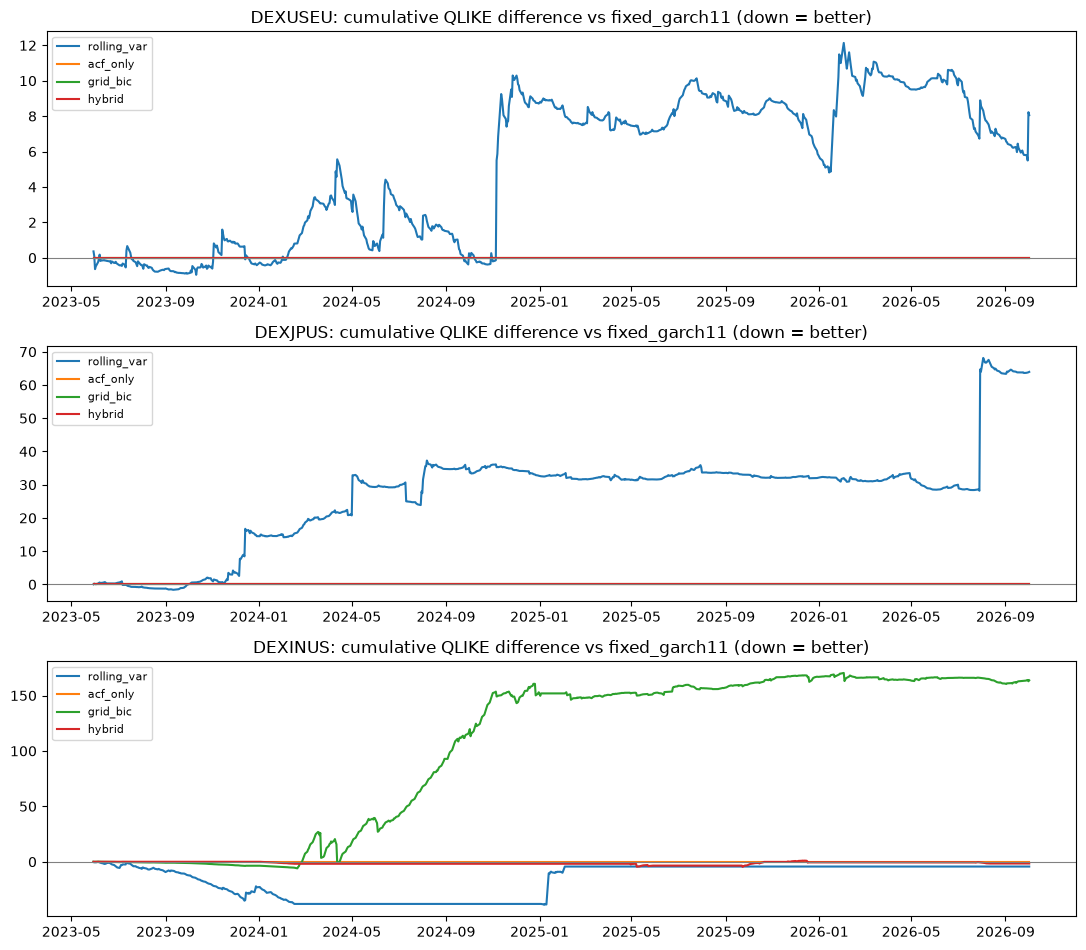

In [4]:
# GOAL: one picture per pair of how each selector's QLIKE drifts away from fixed GARCH(1,1) over the test period.
#
# How to read it: each line is the running sum of (QLIKE of the selector - QLIKE of fixed_garch11). A line that
# goes DOWN means the selector forecasts better than fixed GARCH(1,1) in that stretch; a line that goes UP means
# worse; a flat line at 0 means identical forecasts. The last point is T times the mean difference.

import matplotlib.pyplot as plt                        # plotting
from src.evaluate import cumulative_qlike_diff         # running sum of QLIKE differences, computed in src/

fig, axes = plt.subplots(len(forecasts), 1, figsize=(11, 3.2 * len(forecasts)), sharex=False)

for ax, (pair, fc) in zip(axes, forecasts.items()):
    cum = cumulative_qlike_diff(fc, cfg)               # one column per selector except the baseline
    for sel in cum.columns:
        ax.plot(cum.index, cum[sel], label=sel)
    ax.axhline(0, color='grey', lw=0.8)                # zero line = same as fixed_garch11
    ax.set_title(f'{pair}: cumulative QLIKE difference vs {cfg["evaluate"]["figure_baseline"]} (down = better)')
    ax.legend(loc='best', fontsize=8)

plt.tight_layout()                                     # stop titles/labels overlapping
plt.show()

In [5]:
# GOAL: see WHERE the pooled hybrid-vs-fixed QLIKE difference on USD/INR comes from, one refit block at a time
# (D-029). This describes the difference; it does not test anything.
#
# How to read the output: one row per refit block in which BOTH the hybrid and fixed GARCH(1,1) had a valid fit.
#   hybrid_order / hybrid_dist / fixed_garch11_order = the models in force in that block
#   n_days             = days in the block (the last block can be shorter)
#   block_qlike_diff   = SUM over the block's days of (QLIKE hybrid - QLIKE fixed): NEGATIVE = hybrid better there
#   share_of_total     = this block's value / the total over the listed blocks (the shares add to 1). If a few blocks
#                        hold most of the share, or the signs are mixed, the pooled difference rests on those blocks.
# The total is not 'significant' or 'not significant' by itself; the DM table above holds the tests.

from src.evaluate import block_qlike_diff              # the block split lives in src/evaluate.py

block_pair = cfg['evaluate']['block_pair']             # which pair (USD/INR) comes from config.yaml
blocks = block_qlike_diff(forecasts[block_pair], cfg)  # forecasts were read back from the saved CSVs above

blocks.to_csv(results_dir / 'inr_hybrid_vs_fixed.csv', index=False)   # saved for the report

print(block_pair, ': blocks with both valid =', len(blocks),
      '| total block_qlike_diff =', round(float(blocks['block_qlike_diff'].sum()), 4))
display(blocks)

DEXINUS : blocks with both valid = 10 | total block_qlike_diff = -1.8004


,refit_date,hybrid_order,hybrid_dist,fixed_garch11_order,n_days,block_qlike_diff,share_of_total
0,2023-05-26,"(1, 1)",normal,"(1, 1)",20,0.000000,-0.000000
1,2023-06-27,"(1, 1)",normal,"(1, 1)",20,0.000000,-0.000000
2,2023-07-26,"(1, 1)",normal,"(1, 1)",20,0.000000,-0.000000
3,2023-08-23,"(1, 1)",normal,"(1, 1)",20,0.000000,-0.000000
4,2023-09-21,"(1, 1)",normal,"(1, 1)",20,0.000000,-0.000000
5,2023-10-20,"(1, 1)",normal,"(1, 1)",20,0.000000,-0.000000
6,2023-11-20,"(1, 1)",normal,"(1, 1)",20,0.000000,-0.000000
7,2023-12-19,"(1, 2)",normal,"(1, 1)",20,-0.620176,0.344472
8,2024-01-19,"(1, 2)",normal,"(1, 1)",20,-1.180193,0.655528
9,2025-01-03,"(1, 1)",normal,"(1, 1)",20,0.000000,-0.000000


# P3(c): order-recovery experiment on the eval seeds
Protocol in `docs/decision.md` D-030 (written before any run). The frozen rules (D-023) are applied to simulated series whose true order is known: ARCH(1), GARCH(1,1), GARCH(2,1), GARCH(1,2), GARCH(1,1) with Student-t errors, plus an iid control and an AR(1)+GARCH(1,1) control. Seeds are `eval.seed_base + i`, never the calibration seeds. The hybrid runs at every length in `sim.n`; `grid_bic` only at the lengths in `recovery.grid_n` (30 fits per series).

`recovery.smoke: true` in `config.yaml` runs a quick check (R = `recovery.smoke_R`, lengths `recovery.smoke_n`); set it to `false` for the full run. Nothing here changes a rule. All logic is in `src/simulate.py`; the cells below call it, write `results/recovery_table.csv` and `results/recovery_orders.csv`, and time the run in `results/run_time_recovery.txt`.

In [6]:
# GOAL: run the order-recovery experiment (D-030) with the frozen rules on the eval seeds, write the two
# CSVs, and record how long it took.
#
# How to read the table (one row per true model x length n x selector; every rate is a share of the R
# replications and has a Monte Carlo standard error in the matching *_se column):
#   exact            = final (p, q) equals the true order AND a valid fit existed
#   nesting          = final p >= true p AND final q >= true q (the chosen model CONTAINS the truth; weaker than exact,
#                      over-fitting still counts; carries no information for the iid control, true order (0, 0))
#   family           = the rule's START order picked the right family: (start q >= 1) == (true q >= 1). Hybrid only
#   any_ar_rate      = share given an AR mean: a FALSE-AR rate where the true mean is constant, a detection rate for ar1_garch11
#   gate_pass        = share whose final fit passed the diagnostic gate (hybrid only)
#   escalation_rate  = share that needed more than one fit (hybrid only); mean_fits = average number of fits
#   flagged / no_valid_fit = shares flagged, and shares where every fit was rejected (those never count as exact)
# A difference smaller than about two *_se is noise. The same seeds are used at every n, so rows at different n are
# not independent. Nothing here is a forecast result.

import time                                              # wall-clock timer
from src.simulate import recovery_table                  # the whole experiment lives in src/simulate.py

rec = cfg['recovery']                                    # smoke switch, lengths and true models come from config.yaml
mode = 'smoke' if rec['smoke'] else 'full'
print('recovery mode:', mode)

start = time.perf_counter()
table, orders = recovery_table(cfg)                      # eval seeds only; no rule is changed
elapsed = time.perf_counter() - start

table.to_csv(results_dir / 'recovery_table.csv', index=False)      # saved for the report
orders.to_csv(results_dir / 'recovery_orders.csv', index=False)    # (start order, final order) counts

line = (f'recovery experiment, mode={mode}, R={int(table["R"].iloc[0])}, n={sorted(table["n"].unique().tolist())}, '
        f'elapsed={elapsed:.1f} s')
(results_dir / 'run_time_recovery.txt').write_text(line + '\n')    # timing for planning the full run
print(line)

display(table.round(3))

recovery mode: full


recovery experiment, mode=full, R=500, n=[500, 1000, 4000], elapsed=183.6 s


,true_model,n,selector,R,exact,exact_se,nesting,nesting_se,family,family_se,...,any_ar_se,gate_pass,gate_pass_se,escalation_rate,escalation_se,flagged,flagged_se,no_valid_fit,no_valid_fit_se,mean_fits
0,arch1,500,hybrid,500,0.658,0.021,0.994,0.003,0.844,0.016,...,0.015,0.942,0.010,0.058,0.010,0.058,0.010,0.0,0.0,1.170
1,arch1,1000,hybrid,500,0.606,0.022,1.000,0.000,0.832,0.017,...,0.015,0.938,0.011,0.066,0.011,0.062,0.011,0.0,0.0,1.194
2,arch1,1000,grid_bic,500,0.994,0.003,1.000,0.000,NaN,NaN,...,0.015,NaN,NaN,NaN,NaN,0.000,0.000,0.0,0.0,30.000
3,arch1,4000,hybrid,500,0.452,0.022,1.000,0.000,0.786,0.018,...,0.016,0.948,0.010,0.056,0.010,0.052,0.010,0.0,0.0,1.156
4,garch11,500,hybrid,500,0.766,0.019,0.778,0.019,0.756,0.019,...,0.017,0.934,0.011,0.076,0.012,0.066,0.011,0.0,0.0,1.204
5,garch11,1000,hybrid,500,0.938,0.011,0.958,0.009,0.938,0.011,...,0.017,0.946,0.010,0.080,0.012,0.054,0.010,0.0,0.0,1.204
6,garch11,1000,grid_bic,500,0.982,0.006,0.996,0.003,NaN,NaN,...,0.017,NaN,NaN,NaN,NaN,0.000,0.000,0.0,0.0,30.000
7,garch11,4000,hybrid,500,0.996,0.003,1.000,0.000,1.000,0.000,...,0.018,0.950,0.010,0.054,0.010,0.050,0.010,0.0,0.0,1.158
8,garch21,500,hybrid,500,0.046,0.009,0.052,0.010,0.778,0.019,...,0.016,0.904,0.013,0.122,0.015,0.096,0.013,0.0,0.0,1.316
9,garch21,1000,hybrid,500,0.036,0.008,0.042,0.009,0.956,0.009,...,0.017,0.902,0.013,0.142,0.016,0.098,0.013,0.0,0.0,1.376


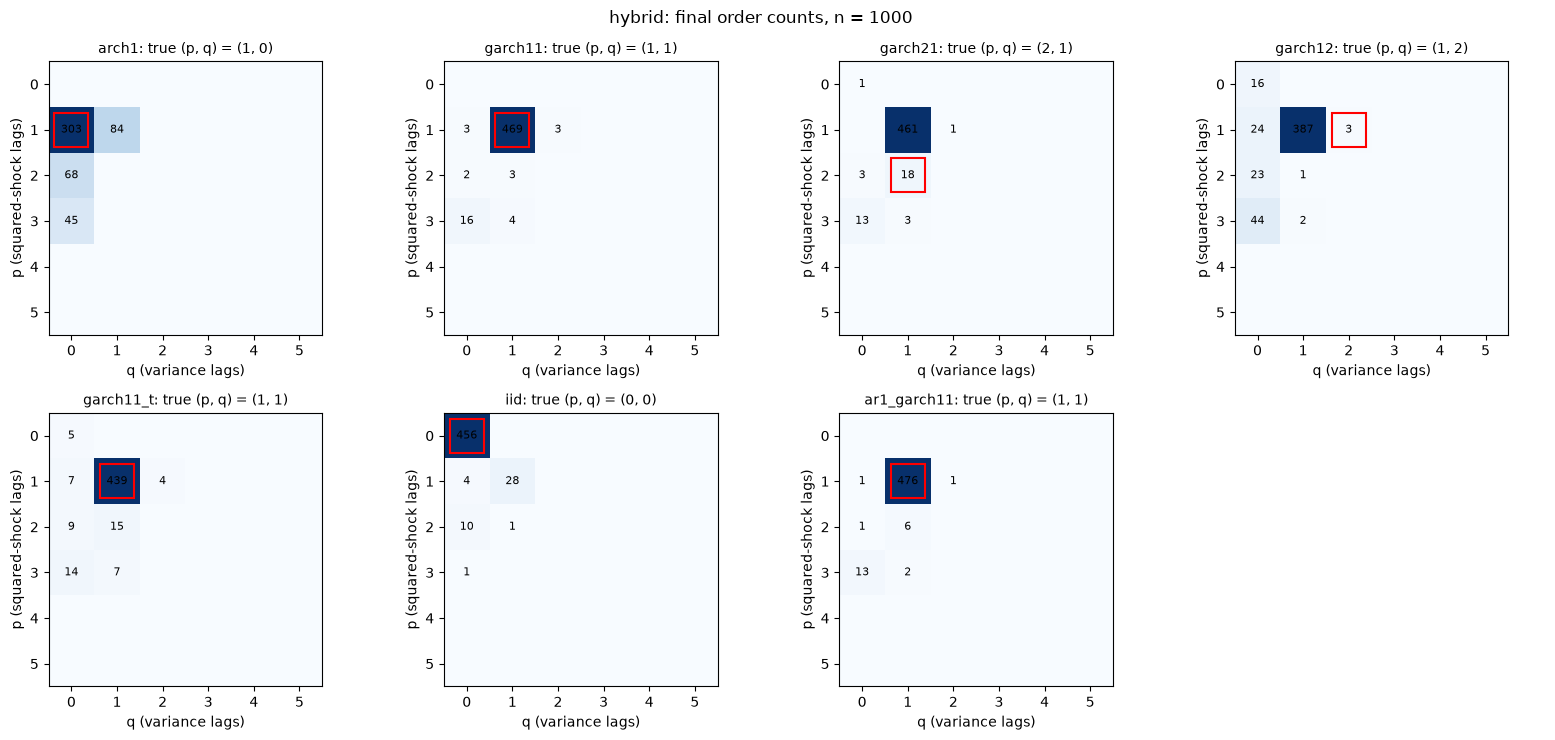

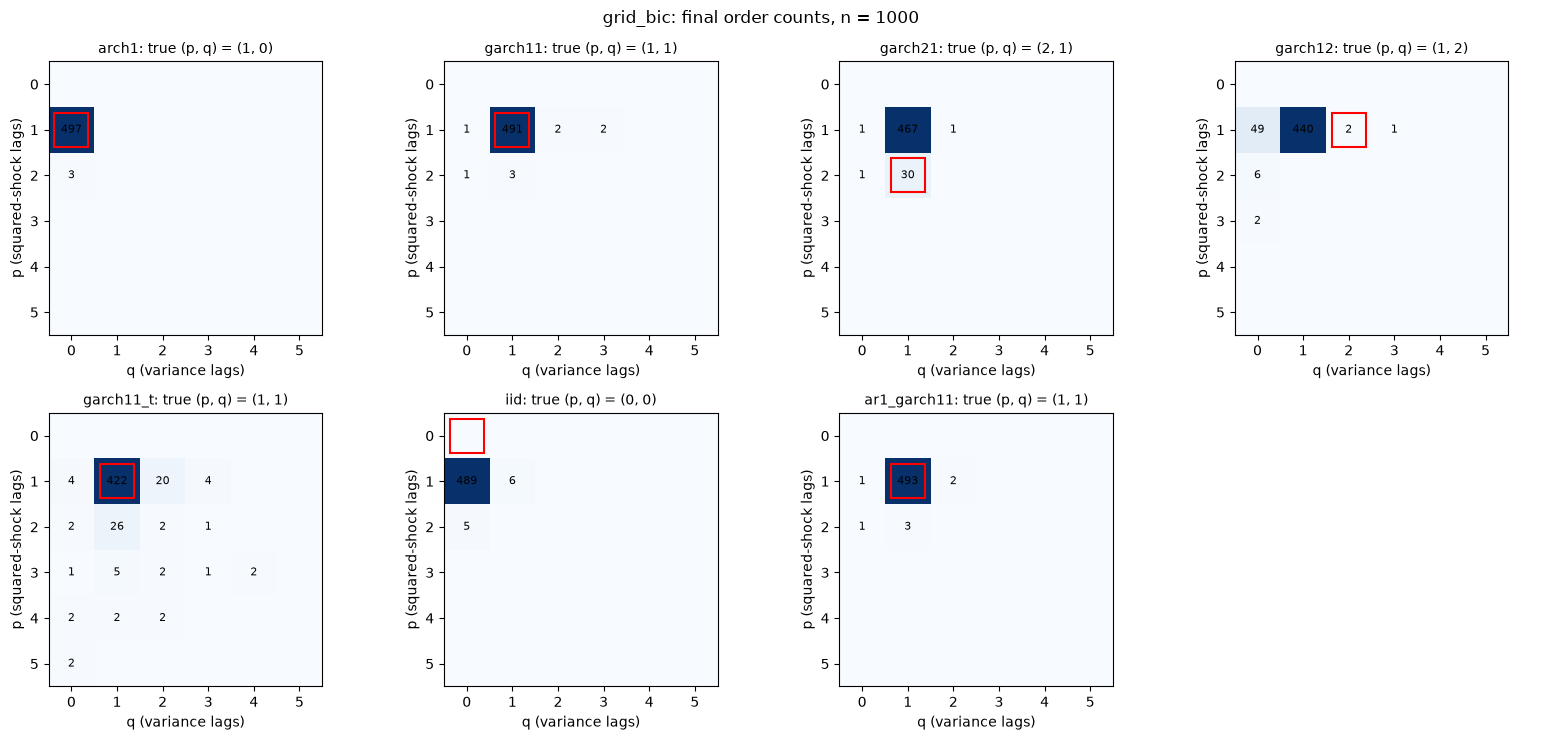

In [7]:
# GOAL: show, for one series length, WHERE the selector ends up. One panel per true model: a grid of final orders
# (rows = p, lags of squared shocks; columns = q, lags of variances), the number in a cell is how many replications ended
# there, and the red square marks the TRUE order.
#
# How to read it: counts piled on the red square = good recovery. Counts to its lower right (more lags) = over-fitting,
# which still 'nests' the truth. Counts above or to the left = under-fitting. One figure per selector; grid_bic is only
# there if it was run at this length (recovery.grid_n). In smoke mode there are only a few replications per panel.

import matplotlib.pyplot as plt                          # plotting
from src.simulate import order_count_matrix, true_spec   # count grid and true order, both computed in src/

n_show = rec['grid_n'][0]                                # a length at which BOTH selectors ran
gmax = cfg['baselines']['grid_max']                      # axes run 0..gmax for p and q (the grid's largest order)
models = list(rec['models'])

for sel in orders[orders['n'] == n_show]['selector'].unique():
    fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))

    for ax, tm in zip(axes.ravel(), models):
        mat = order_count_matrix(orders, tm, n_show, sel, gmax, gmax)
        ax.imshow(mat.to_numpy(), cmap='Blues')

        # Write the count in every non-empty cell.
        for p in range(gmax + 1):
            for q in range(gmax + 1):
                if mat.loc[p, q] > 0:
                    ax.text(q, p, int(mat.loc[p, q]), ha='center', va='center', fontsize=8)

        # Red square on the true order (q on the horizontal axis, p on the vertical axis).
        truth = true_spec(rec['models'][tm])
        ax.plot(truth['q'], truth['p'], marker='s', markersize=24, mfc='none', mec='red', mew=1.5)

        ax.set_xticks(range(gmax + 1))
        ax.set_yticks(range(gmax + 1))
        ax.set_xlabel('q (variance lags)')
        ax.set_ylabel('p (squared-shock lags)')
        ax.set_title(f'{tm}: true (p, q) = ({truth["p"]}, {truth["q"]})', fontsize=10)

    for ax in axes.ravel()[len(models):]:
        ax.axis('off')                                   # unused panel (7 models in a 2 x 4 grid)

    fig.suptitle(f'{sel}: final order counts, n = {n_show}')
    plt.tight_layout()                                   # stop titles/labels overlapping
    plt.show()

In [8]:
# POST-HOC DIAGNOSTIC (D-031), added after seeing the eval recovery table. It changes no rule, threshold or existing result.
#
# GOAL: test one explanation of why ARCH(1) exact recovery FALLS as n grows (D-030 run: 0.658 / 0.606 / 0.452).
# Hypothesis: the 1.96 / sqrt(n) band is too narrow for the PACF of squares when the 8th moment of the returns is
# infinite (normal ARCH(1) with alpha above about 0.31), so chance PACF spikes at lags 2..5 are too frequent and
# push the start order away from (1, 0). We simulate ARCH(1) with alpha 0.2 (below that value) and 0.4 (above it).
#
# How to read the table (one row per alpha x n; every rate is a share of R replications, *_se = Monte Carlo SE):
#   exact / nesting   = as in the recovery table above (frozen hybrid, new seeds: diagnostic.seed_base + i)
#   false_spike_rate  = share of the SIMULATED RETURNS (constant mean, no model fitted, same band as the rules) whose
#                       PACF of squares has at least one bar outside the band in lags 2..5. For white noise about 0.19
#                       is expected by chance; a true ARCH(1) has no PACF-of-squares structure beyond lag 1.
# The verdict (fixed in D-031 before any number) is 'supported' only if alpha 0.2 exact does not fall by more than 0.05
# from the smallest to the largest n, AND alpha 0.4 exact falls by more than 0.05, AND its false_spike_rate rises by
# more than 0.05. Otherwise it is 'unexplained'. 'Supported' means consistent with the hypothesis, not proved; the
# late-lag ACF 'fade' rule is not measured here. The same seeds are used at every n and alpha (paired cells).

import time                                                       # wall-clock timer
from src.simulate import diagnostic_arch1_table, diagnostic_verdict   # all logic lives in src/simulate.py

dg = cfg['diagnostic']                                            # switch, alphas, lengths, R and seeds come from config.yaml

if not dg['enabled']:
    print('diagnostic.enabled is false: diagnostic skipped')
else:
    start = time.perf_counter()
    diag = diagnostic_arch1_table(cfg)                            # hybrid recovery + false-spike rate; eval and calibration seeds untouched
    elapsed = time.perf_counter() - start

    diag.to_csv(results_dir / 'diagnostic_arch1.csv', index=False)    # saved for the report
    print(f'diagnostic: R={dg["R"]}, n={dg["n"]}, alphas={dg["alphas"]}, elapsed={elapsed:.1f} s')
    display(diag.round(3))

    for key, value in diagnostic_verdict(diag, cfg).items():      # the three changes (largest n minus smallest n), the booleans, the verdict
        print(f'{key}: {value}')

diagnostic: R=500, n=[500, 1000, 4000], alphas=[0.2, 0.4], elapsed=7.8 s


,alpha,n,R,exact,nesting,false_spike_rate,exact_se,nesting_se,false_spike_se
0,0.2,500,500,0.604,0.840,0.216,0.022,0.016,0.018
1,0.2,1000,500,0.718,0.978,0.226,0.020,0.007,0.019
2,0.2,4000,500,0.724,1.000,0.228,0.020,0.000,0.019
3,0.4,500,500,0.640,0.996,0.316,0.021,0.003,0.021
4,0.4,1000,500,0.592,1.000,0.378,0.022,0.000,0.022
5,0.4,4000,500,0.500,1.000,0.472,0.022,0.000,0.022


change_exact_low_alpha: 0.12
change_exact_high_alpha: -0.14
change_spike_high_alpha: 0.15599999999999997
low_alpha_flat: True
high_alpha_falls: True
high_alpha_spike_rises: True
verdict: supported
